<a href="https://colab.research.google.com/github/Varshh-hub/Image-Classification-System-Using-DL/blob/main/classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

BATCH_SIZE = 64
CNN_EPOCHS = 4
TRANSFER_EPOCHS = 4
TRANSFER_TRAIN_LIMIT = 30000
IMAGE_SIZE = 96
OUTPUT_DIR = "artifacts"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

TensorFlow: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
y_train = y_train.squeeze().astype("int64")
y_test = y_test.squeeze().astype("int64")

print("Training images:", x_train.shape)
print("Test images:", x_test.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)
print("Classes:", class_names)
print("Pixel range:", int(x_train.min()), int(x_train.max()))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step
Training images: (50000, 32, 32, 3)
Test images: (10000, 32, 32, 3)
Training labels: (50000,)
Test labels: (10000,)
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Pixel range: 0 255


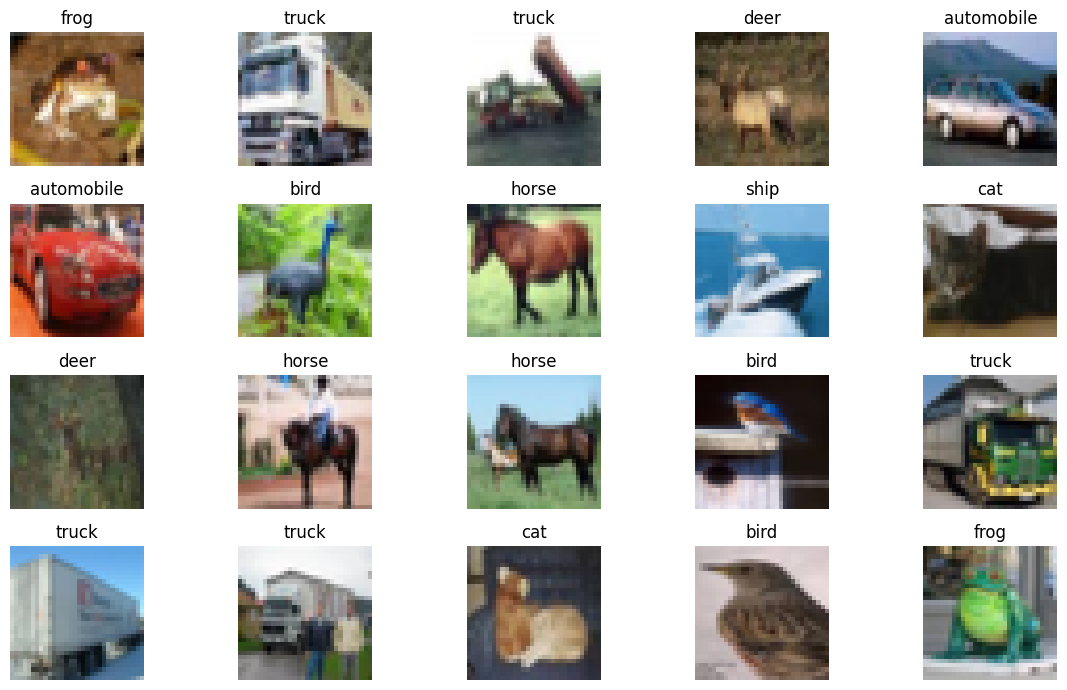

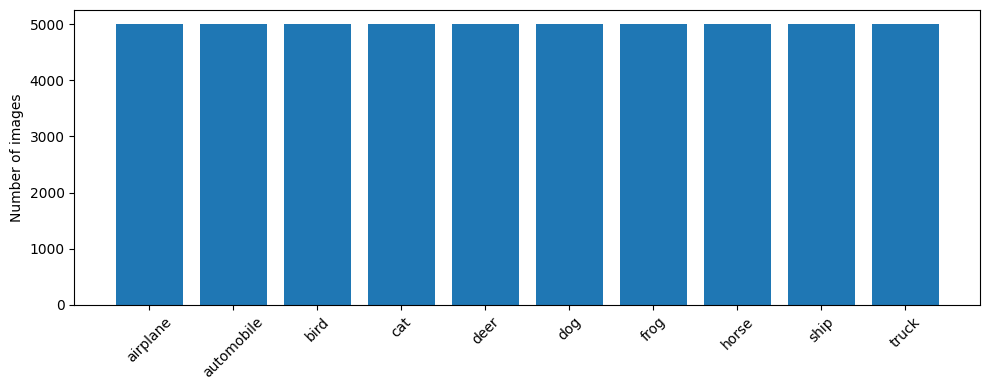

In [3]:
plt.figure(figsize=(12, 7))
for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

counts = np.bincount(y_train, minlength=10)
plt.figure(figsize=(10, 4))
plt.bar(class_names, counts)
plt.xticks(rotation=45)
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.1, random_state=SEED, stratify=y_train
)

train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train))
train_ds = train_ds.shuffle(20000, seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Train:", x_train.shape, "Validation:", x_val.shape, "Test:", x_test.shape)

Train: (45000, 32, 32, 3) Validation: (5000, 32, 32, 3) Test: (10000, 32, 32, 3)


In [5]:
def build_cnn():
    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.25)(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.35)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="custom_cnn")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

cnn_model = build_cnn()
cnn_model.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 158,122 (617.66 KB)

 Trainable params: 157,674 (615.91 KB)

 Non-trainable params: 448 (1.75 KB)

In [6]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    keras.callbacks.ModelCheckpoint(os.path.join(OUTPUT_DIR, "best_cnn.keras"), monitor="val_accuracy", save_best_only=True)
]

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CNN_EPOCHS,
    callbacks=callbacks
)

Epoch 1/4
704/704 ━━━━━━━━━━━━━━━━━━━━ 319s 447ms/step - accuracy: 0.4374 - loss: 1.5311 - val_accuracy: 0.5122 - val_loss: 1.3464 - learning_rate: 0.0010
Epoch 2/4
704/704 ━━━━━━━━━━━━━━━━━━━━ 393s 559ms/step - accuracy: 0.5866 - loss: 1.1550 - val_accuracy: 0.6252 - val_loss: 1.0432 - learning_rate: 0.0010
Epoch 3/4
704/704 ━━━━━━━━━━━━━━━━━━━━ 320s 455ms/step - accuracy: 0.6373 - loss: 1.0187 - val_accuracy: 0.6832 - val_loss: 0.9080 - learning_rate: 0.0010
Epoch 4/4
704/704 ━━━━━━━━━━━━━━━━━━━━ 312s 444ms/step - accuracy: 0.6744 - loss: 0.9261 - val_accuracy: 0.6678 - val_loss: 0.9108 - learning_rate: 0.0010


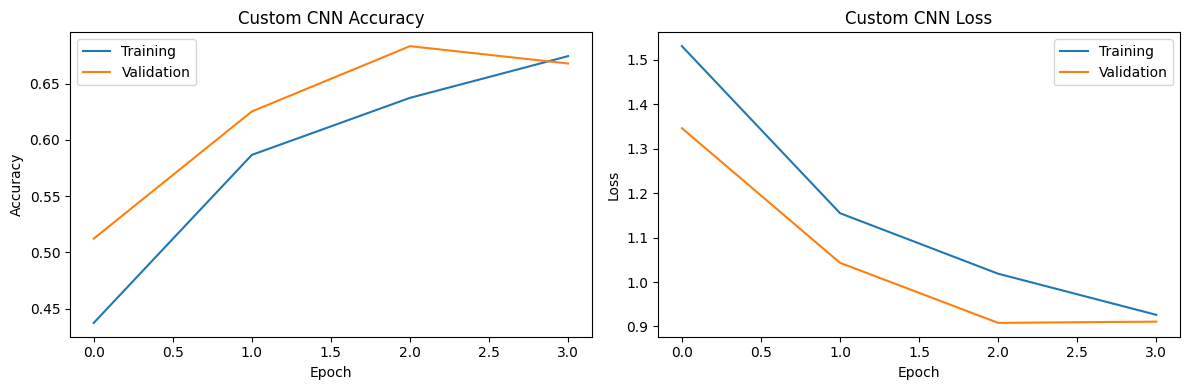

In [7]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history["accuracy"], label="Training")
    axes[0].plot(history.history["val_accuracy"], label="Validation")
    axes[0].set_title(title + " Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[1].plot(history.history["loss"], label="Training")
    axes[1].plot(history.history["val_loss"], label="Validation")
    axes[1].set_title(title + " Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(cnn_history, "Custom CNN")

CNN test loss: 0.9262
CNN test accuracy: 0.669
              precision    recall  f1-score   support

    airplane     0.7444    0.5970    0.6626      1000
  automobile     0.8583    0.8540    0.8561      1000
        bird     0.4919    0.5460    0.5175      1000
         cat     0.4868    0.4430    0.4639      1000
        deer     0.7057    0.4460    0.5466      1000
         dog     0.5455    0.6290    0.5843      1000
        frog     0.5933    0.8200    0.6885      1000
       horse     0.8101    0.6270    0.7069      1000
        ship     0.7668    0.8680    0.8143      1000
       truck     0.7748    0.8600    0.8152      1000

    accuracy                         0.6690     10000
   macro avg     0.6778    0.6690    0.6656     10000
weighted avg     0.6778    0.6690    0.6656     10000



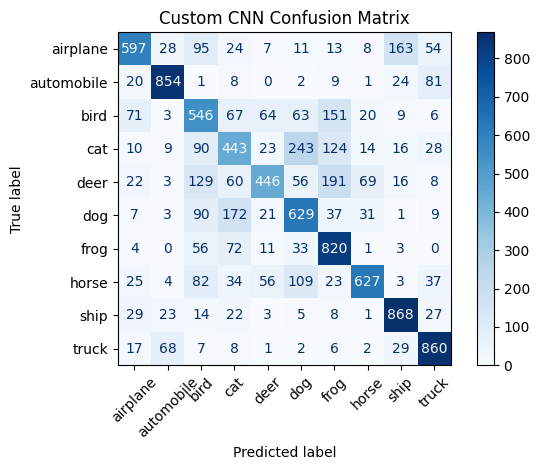

In [8]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(test_ds, verbose=0)
cnn_probabilities = cnn_model.predict(test_ds, verbose=0)
cnn_predictions = np.argmax(cnn_probabilities, axis=1)

print("CNN test loss:", round(float(cnn_test_loss), 4))
print("CNN test accuracy:", round(float(cnn_test_accuracy), 4))
print(classification_report(y_test, cnn_predictions, target_names=class_names, digits=4))

cnn_cm = confusion_matrix(y_test, cnn_predictions)
ConfusionMatrixDisplay(cnn_cm, display_labels=class_names).plot(xticks_rotation=45, cmap="Blues", values_format="d")
plt.title("Custom CNN Confusion Matrix")
plt.tight_layout()
plt.show()

cnn_model.save(os.path.join(OUTPUT_DIR, "custom_cnn_final.keras"))

In [9]:
transfer_train_count = min(TRANSFER_TRAIN_LIMIT, len(x_train))
transfer_indices = np.random.default_rng(SEED).choice(len(x_train), transfer_train_count, replace=False)

def make_transfer_dataset(images, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(min(len(images), 20000), seed=SEED)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(
        lambda image, label: (tf.image.resize(image, (IMAGE_SIZE, IMAGE_SIZE)), label),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    return ds.prefetch(tf.data.AUTOTUNE)

transfer_train_ds = make_transfer_dataset(x_train[transfer_indices], y_train[transfer_indices], training=True)
transfer_val_ds = make_transfer_dataset(x_val, y_val)
transfer_test_ds = make_transfer_dataset(x_test, y_test)

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1)
])

base_model = keras.applications.MobileNetV2(
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(scale=2.0, offset=-1.0)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)

transfer_model = keras.Model(inputs, outputs, name="mobilenetv2_transfer_learning")
transfer_model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
transfer_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "mobilenetv2_transfer_learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,588,490 (9.87 MB)

 Trainable params: 330,506 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [12]:
transfer_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    keras.callbacks.ModelCheckpoint(os.path.join(OUTPUT_DIR, "best_transfer.keras"), monitor="val_accuracy", save_best_only=True)
]

transfer_history = transfer_model.fit(
    transfer_train_ds,
    validation_data=transfer_val_ds,
    epochs=TRANSFER_EPOCHS,
    callbacks=transfer_callbacks
)

Epoch 1/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 332s 706ms/step - accuracy: 0.6868 - loss: 0.9060 - val_accuracy: 0.8160 - val_loss: 0.5552 - learning_rate: 0.0010
Epoch 2/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 312s 665ms/step - accuracy: 0.7225 - loss: 0.7984 - val_accuracy: 0.8268 - val_loss: 0.5230 - learning_rate: 0.0010
Epoch 3/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 319s 681ms/step - accuracy: 0.7356 - loss: 0.7609 - val_accuracy: 0.8316 - val_loss: 0.5060 - learning_rate: 0.0010
Epoch 4/4
469/469 ━━━━━━━━━━━━━━━━━━━━ 413s 880ms/step - accuracy: 0.7473 - loss: 0.7327 - val_accuracy: 0.8286 - val_loss: 0.5078 - learning_rate: 0.0010


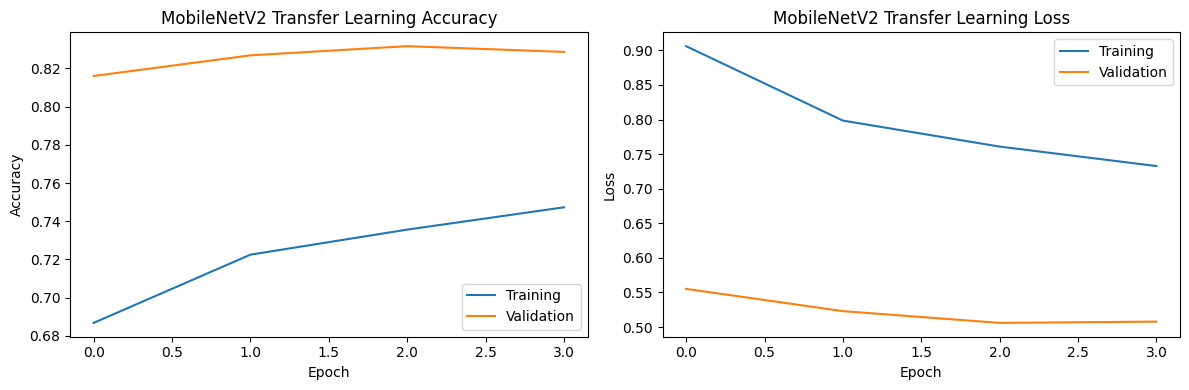

In [13]:
plot_history(transfer_history, "MobileNetV2 Transfer Learning")

Transfer learning test loss: 0.5154
Transfer learning test accuracy: 0.8253
              precision    recall  f1-score   support

    airplane     0.8880    0.7930    0.8378      1000
  automobile     0.8528    0.9330    0.8911      1000
        bird     0.8373    0.7720    0.8033      1000
         cat     0.8378    0.5370    0.6545      1000
        deer     0.7813    0.8290    0.8045      1000
         dog     0.7344    0.8350    0.7815      1000
        frog     0.8639    0.8630    0.8634      1000
       horse     0.8443    0.8570    0.8506      1000
        ship     0.8789    0.8930    0.8859      1000
       truck     0.7700    0.9410    0.8470      1000

    accuracy                         0.8253     10000
   macro avg     0.8289    0.8253    0.8220     10000
weighted avg     0.8289    0.8253    0.8220     10000



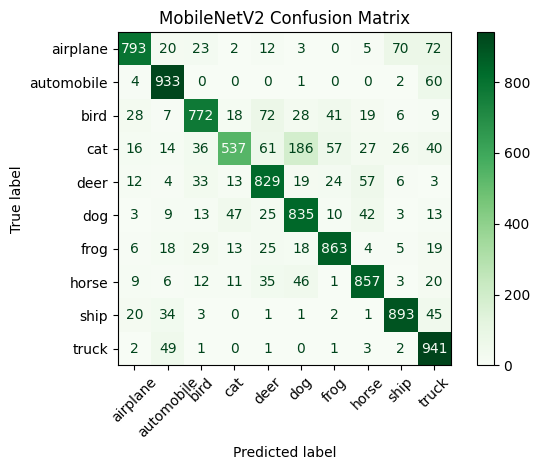

In [18]:
transfer_test_loss, transfer_test_accuracy = transfer_model.evaluate(transfer_test_ds, verbose=0)
transfer_probabilities = transfer_model.predict(transfer_test_ds, verbose=0)
transfer_predictions = np.argmax(transfer_probabilities, axis=1)

print("Transfer learning test loss:", round(float(transfer_test_loss), 4))
print("Transfer learning test accuracy:", round(float(transfer_test_accuracy), 4))
print(classification_report(y_test, transfer_predictions, target_names=class_names, digits=4))

transfer_cm = confusion_matrix(y_test, transfer_predictions)
ConfusionMatrixDisplay(transfer_cm, display_labels=class_names).plot(xticks_rotation=45, cmap="Greens", values_format="d")
plt.title("MobileNetV2 Confusion Matrix")
plt.tight_layout()
plt.show()

transfer_model.save(os.path.join(OUTPUT_DIR, "mobilenetv2_transfer_final.keras"))

In [21]:
comparison = {
    "Model": ["Custom CNN", "MobileNetV2 Transfer Learning"],
    "Test Loss": [float(cnn_test_loss), float(transfer_test_loss)],
    "Test Accuracy": [float(cnn_test_accuracy), float(transfer_test_accuracy)]
}
for model_name, loss_value, accuracy_value in zip(comparison["Model"], comparison["Test Loss"], comparison["Test Accuracy"]):
    print(f"{model_name}: loss={loss_value:.4f}, accuracy={accuracy_value:.4f}")

best_model_name = comparison["Model"][int(np.argmax(comparison["Test Accuracy"]))]
print("Best model based on test accuracy:", best_model_name)

Custom CNN: loss=0.9262, accuracy=0.6690
MobileNetV2 Transfer Learning: loss=0.5154, accuracy=0.8253
Best model based on test accuracy: MobileNetV2 Transfer Learning


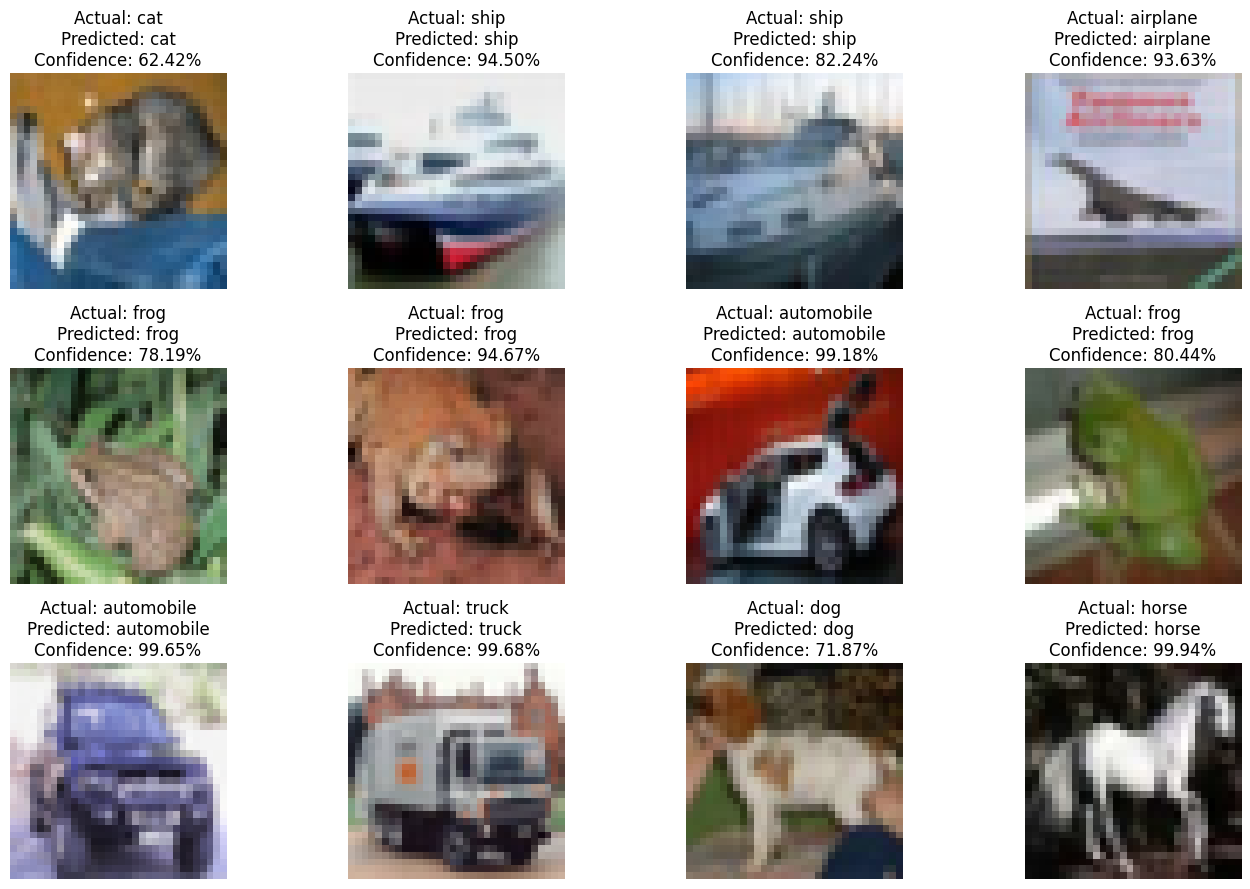

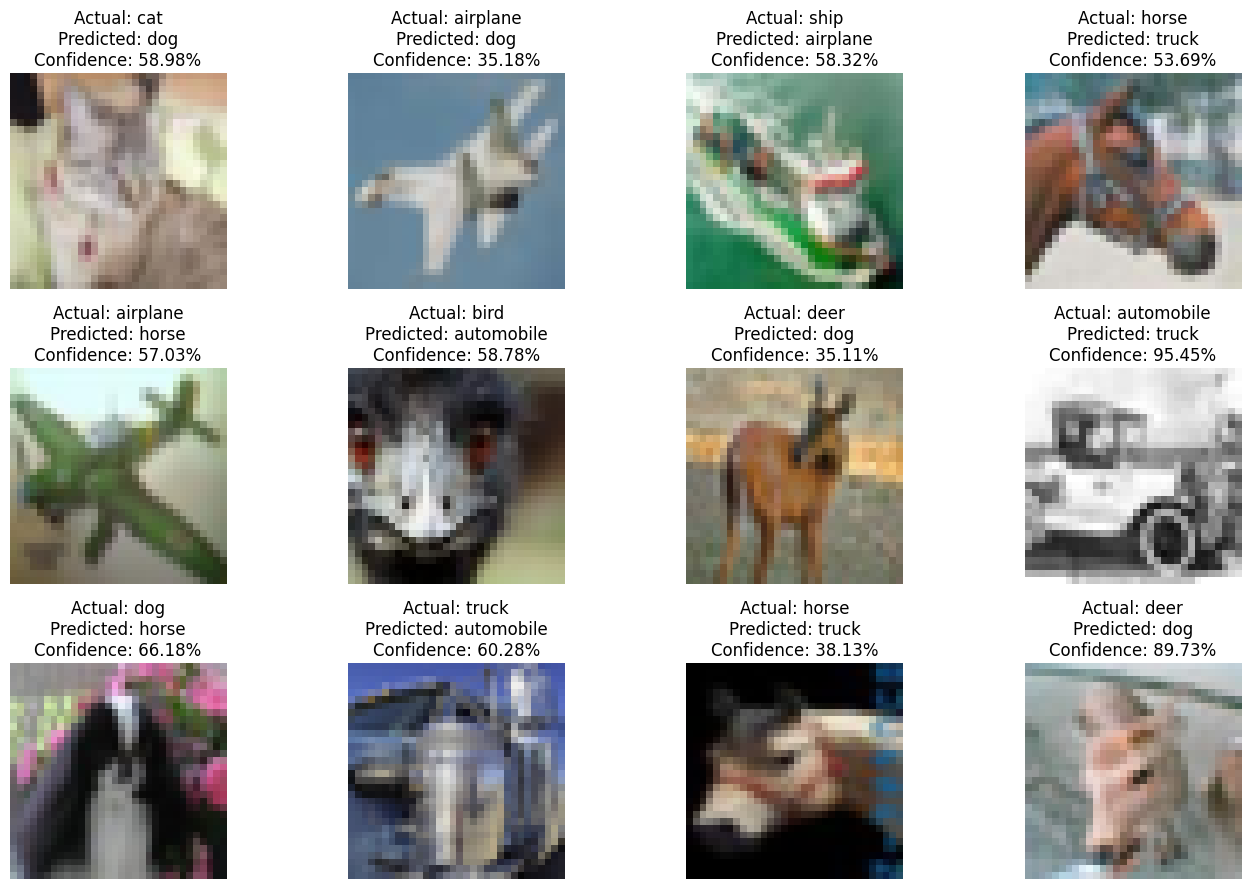

In [22]:
def show_predictions(images, labels, predictions, probabilities, correct=True, count=12):
    selected = np.where(predictions == labels)[0] if correct else np.where(predictions != labels)[0]
    if len(selected) == 0:
        print("No matching examples found.")
        return
    selected = selected[:count]
    columns = 4
    rows = int(np.ceil(len(selected) / columns))
    plt.figure(figsize=(14, rows * 3))
    for position, index in enumerate(selected, 1):
        plt.subplot(rows, columns, position)
        plt.imshow(images[index])
        confidence = float(np.max(probabilities[index]))
        plt.title(
            f"Actual: {class_names[labels[index]]}\nPredicted: {class_names[predictions[index]]}\nConfidence: {confidence:.2%}"
        )
        plt.axis("off")
    plt.tight_layout()
    plt.show()

show_predictions(x_test, y_test, transfer_predictions, transfer_probabilities, correct=True)
show_predictions(x_test, y_test, transfer_predictions, transfer_probabilities, correct=False)

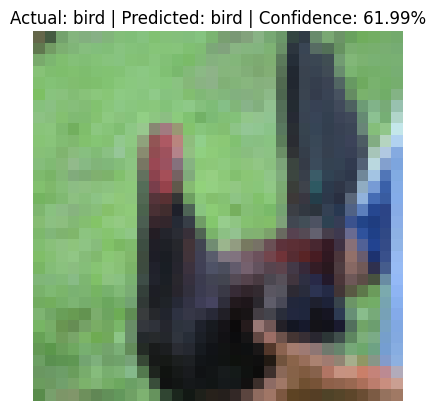

In [23]:
def predict_image(image, model="transfer"):
    image = np.asarray(image)
    if image.max() > 1:
        image = image.astype("float32") / 255.0
    if model == "cnn":
        resized = tf.image.resize(image, (32, 32))
        probabilities = cnn_model.predict(tf.expand_dims(resized, 0), verbose=0)[0]
    else:
        resized = tf.image.resize(image, (IMAGE_SIZE, IMAGE_SIZE))
        probabilities = transfer_model.predict(tf.expand_dims(resized, 0), verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    return class_names[predicted_index], float(probabilities[predicted_index]), probabilities

sample_index = 25
predicted_label, confidence, all_scores = predict_image((x_test[sample_index] * 255).astype("uint8"))
plt.imshow(x_test[sample_index])
plt.axis("off")
plt.title(f"Actual: {class_names[y_test[sample_index]]} | Predicted: {predicted_label} | Confidence: {confidence:.2%}")
plt.show()

In [24]:
results_path = os.path.join(OUTPUT_DIR, "evaluation_results.txt")
with open(results_path, "w", encoding="utf-8") as file:
    file.write("CUSTOM CNN\n")
    file.write(f"Test loss: {cnn_test_loss:.6f}\n")
    file.write(f"Test accuracy: {cnn_test_accuracy:.6f}\n")
    file.write(classification_report(y_test, cnn_predictions, target_names=class_names))
    file.write("\nMOBILENETV2 TRANSFER LEARNING\n")
    file.write(f"Test loss: {transfer_test_loss:.6f}\n")
    file.write(f"Test accuracy: {transfer_test_accuracy:.6f}\n")
    file.write(classification_report(y_test, transfer_predictions, target_names=class_names))
print("Saved models and evaluation results in:", OUTPUT_DIR)

Saved models and evaluation results in: artifacts


In [25]:
import os

for root, dirs, files in os.walk('/content/artifacts'):
    for file in files:
        print(os.path.join(root, file))

/content/artifacts/custom_cnn_final.keras
/content/artifacts/best_transfer.keras
/content/artifacts/best_cnn.keras
/content/artifacts/evaluation_results.txt
/content/artifacts/mobilenetv2_transfer_final.keras


In [26]:
import shutil
from google.colab import files

shutil.make_archive(
    '/content/artifacts',
    'zip',
    '/content/artifacts'
)

files.download('/content/artifacts.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
import os

for folder in ['/content', '/content/drive/MyDrive']:
    if os.path.exists(folder):
        print(f"\n--- {folder} ---")
        for item in os.listdir(folder):
            print(item)


--- /content ---
.config
artifacts.zip
artifacts
sample_data
